# Tema 3 · Empresas — sonda pequeña (10 empresas)

**Fase 2 del TFM** (datos de los agentes) · rama `fase2/t3-empresas` · responsable: Daniel.

Antes de descargar el universo entero, el equipo acordó probar cada fuente con poco volumen y **medir**:
qué datos hay, desde cuándo, con qué retraso se publican, cuánto ocupan y qué falla. Este notebook hace
esa prueba para la parte de empresas con 10 compañías:

| | Empresas |
|---|---|
| S&P 500 actual (sectores distintos, historia larga) | Apple, Microsoft, JPMorgan, Exxon, Johnson & Johnson, Walmart, Coca-Cola, General Electric |
| Desaparecidas (sesgo de supervivencia) | Lehman Brothers (quiebra 2008), Enron (quiebra 2001) |

**Fuentes** (todas de la SEC, gratis y sin clave):

1. **Filings de EDGAR**: 10-K (anual), 10-Q (trimestral) y 8-K de resultados, troceados por secciones.
2. **Fundamentales XBRL** (`companyfacts`): cifras contables tal como se conocían en cada fecha.
3. **Sentimiento** con el diccionario Loughran-McDonald, y `risk_delta` (cuánto cambian los riesgos declarados de un año a otro).

El código vive en `src/ingesta/empresas/` (un módulo por pieza, con tests). Este notebook solo lo ejecuta
y enseña los resultados.

### Antes de ejecutar

1. En `.env`: `SEC_EDGAR_USER_AGENT=Nombre Apellido tu@email.com` (la SEC lo exige) y, si quieres,
   `INGESTA_CORPUS_DIR=` con una carpeta con espacio (por defecto `./corpus`, fuera de git).
2. Para el sentimiento: descarga el *Master Dictionary* de
   [sraf.nd.edu](https://sraf.nd.edu/loughranmcdonald-master-dictionary/) y déjalo en `<corpus>/empresas/lm/`.
   Sin él, el notebook se salta ese paso y sigue.
3. **Tiempo**: con `MODO_RAPIDO = True` (3 informes por tipo y empresa) tarda unos minutos. Con `False`
   baja todo el histórico (≈1.000–2.000 filings; del orden de una hora a 5 peticiones/s). Todo se cachea:
   repetir es instantáneo.

## 1. Configuración

`ConfigSonda` reúne las opciones. `usar_cache=True` reutiliza lo ya descargado en el corpus.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from ingesta.comun.http import user_agent
from ingesta.comun.rutas import corpus_dir, resultados_dir
from ingesta.empresas import sentimiento, sonda, xbrl
from ingesta.empresas.universo import MUESTRA_SONDA

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

MODO_RAPIDO = True          # True: 3 informes por tipo y empresa · False: todo el histórico

ua = user_agent()
if '@' not in ua:
    raise RuntimeError('Pon SEC_EDGAR_USER_AGENT="Nombre Apellido email@dominio" en .env: la SEC lo exige.')

cfg = sonda.ConfigSonda(
    empresas=MUESTRA_SONDA,
    familias=('10-K', '10-Q'),
    resultados_8k=True,
    max_por_familia=3 if MODO_RAPIDO else None,
)
print('User-Agent :', ua)
print('Corpus     :', corpus_dir('empresas'))
print('Resultados :', resultados_dir('empresas'))
print('Empresas   :', ', '.join(e.ticker for e in cfg.empresas))
print('Modo       :', 'rápido (3 por tipo)' if MODO_RAPIDO else 'histórico completo')

User-Agent : Daniel Garcia danielgarcialop18@gmail.com
Corpus     : C:\Users\danie\Desktop\MIAX - BME\TFM\PRUEBAS_DETECCION_REGIMENES_DE_MERCADO_TFM\corpus\empresas
Resultados : C:\Users\danie\Desktop\MIAX - BME\TFM\PRUEBAS_DETECCION_REGIMENES_DE_MERCADO_TFM\results\ingesta\empresas
Empresas   : AAPL, MSFT, JPM, XOM, JNJ, WMT, KO, GE, LEH, ENRNQ
Modo       : rápido (3 por tipo)


## 2. Lista de filings y TimeGate

Para cada empresa se pide a la SEC la lista **completa** de lo que ha presentado (la API devuelve los ~1.000
más recientes y el resto en páginas aparte; se leen todas). Cada filing recibe su `fecha_publicacion`:

- `filingDate` si la SEC lo aceptó antes de las 16:00 de Nueva York (cierre del mercado);
- el **siguiente día hábil** si lo aceptó después: el mercado no pudo usarlo hasta la sesión siguiente.

La hora de aceptación se lee de la **cabecera oficial** de cada filing (`.hdr.sgml`): la que da la API viene
desfasada (lo vemos en 3.1). Por eso `paso1_filings` asigna primero una fecha prudente (día hábil siguiente)
y `verificar_timegate` lee la cabecera de los filings que vamos a descargar y les pone la fecha definitiva.
Esta fecha es la que usará el TimeGate: un agente que decide el día *t* nunca verá nada con
`fecha_publicacion > t`.

In [2]:
filings = sonda.paso1_filings(cfg)
print(f'\n{len(filings):,} filings en total')
display(filings.groupby(['ticker', 'familia'], dropna=False).size().unstack(fill_value=0))

  AAPL    2265 filings (0.0 s)
  MSFT    4525 filings (1.0 s)
  JPM    168775 filings (33.6 s)
  XOM     3557 filings (1.2 s)
  JNJ     3371 filings (1.1 s)
  WMT     4425 filings (0.9 s)
  KO      3303 filings (1.0 s)
  GE      4782 filings (1.0 s)
  LEH     6341 filings (2.0 s)
  ENRNQ    351 filings (0.4 s)

201,695 filings en total


familia,10-K,10-Q,8-K,NaN
ticker,,,,
AAPL,34,100,236,1895
ENRNQ,5,18,83,245
GE,35,109,375,4263
JNJ,43,107,324,2897
JPM,43,100,1378,167254
KO,34,102,347,2820
LEH,18,46,575,5702
MSFT,33,104,286,4102
WMT,35,97,340,3953


In [3]:
filings = sonda.verificar_timegate(filings, cfg)   # una petición pequeña por filing seleccionado (cacheada)

  81 de 87 filings con hora oficial (29.8 s)


## 3. Cobertura: desde cuándo hay datos y con qué retraso

Para cada empresa y tipo de informe: cuántos hay, el primero y el último, el **retraso** entre el cierre del
periodo y la publicación (mediana y percentiles 10–90) y qué parte se publicó **tras el cierre del mercado**.

Cómo leerlo:

- `primero` responde a *¿desde qué año podemos empezar?* EDGAR electrónico arranca en 1993–1996 según la empresa.
- `retraso_*` es el lag que el TimeGate tiene que respetar (un 10-K sale semanas después de cerrar el ejercicio).
- Lehman y Enron deben aparecer: si no, habría sesgo de supervivencia.

In [4]:
cobertura = sonda.medir_cobertura(filings)
display(cobertura.round(2))

resumen = (cobertura.groupby('familia')
           .agg(empresas=('ticker', 'nunique'), primero=('primero', 'min'),
                retraso_mediana_d=('retraso_mediana_d', 'median'), pct_tras_cierre=('pct_tras_cierre', 'mean'))
           .round(2))
display(resumen)

,ticker,familia,n,primero,ultimo,retraso_mediana_d,retraso_p10_d,retraso_p90_d,n_hora_oficial,pct_tras_cierre,pct_html,pct_xbrl
0,AAPL,10-K,32,1994-12-13,2025-10-31,35.5,32.0,83.0,3,0.00,0.78,0.53
1,AAPL,10-Q,98,1994-01-26,2026-07-31,34.0,25.0,45.0,3,0.00,0.79,0.53
2,AAPL,8-K otros,135,1996-04-12,2026-04-20,3.0,0.0,7.0,0,NaN,0.88,0.26
3,AAPL,8-K resultados,98,2003-10-15,2026-07-30,0.0,0.0,0.0,3,1.00,1.00,0.31
4,ENRNQ,10-K,5,1997-03-28,2001-04-02,90.0,88.2,91.2,0,NaN,0.00,0.00
5,ENRNQ,10-Q,16,1996-11-25,2001-11-19,45.0,45.0,48.5,0,NaN,0.00,0.00
6,ENRNQ,8-K otros,82,1997-07-16,2004-11-18,1.0,0.0,10.8,0,NaN,0.01,0.00
7,GE,10-K,33,1994-03-11,2026-01-29,57.0,35.4,81.6,3,0.00,0.79,0.52
8,GE,10-Q,98,1994-05-13,2026-07-16,30.0,22.7,43.0,3,0.00,0.82,0.53
9,GE,8-K otros,270,1994-04-28,2026-09-22,1.0,0.0,6.0,0,NaN,0.96,0.36


,empresas,primero,retraso_mediana_d,pct_tras_cierre
familia,,,,
10-K,10,1994-03-11,58.0,0.63
10-Q,10,1994-01-26,35.5,0.48
8-K otros,10,1994-01-21,1.0,NaN
8-K resultados,9,2003-07-31,0.0,0.22


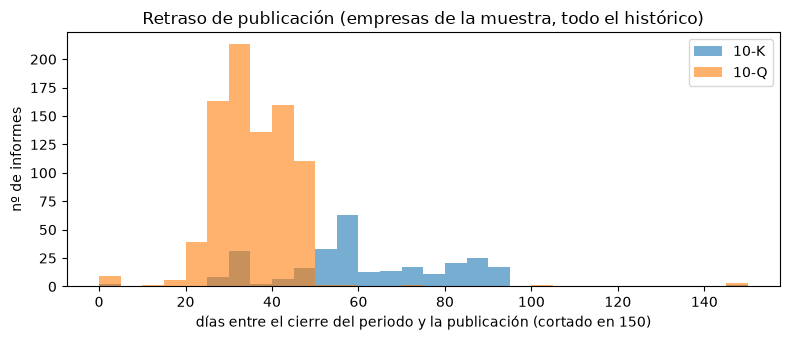

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
datos = filings.loc[filings['familia'].isin(['10-K', '10-Q']) & ~filings['enmienda']]
for fam in ['10-K', '10-Q']:
    ax.hist(datos.loc[datos['familia'] == fam, 'retraso_dias'].dropna().clip(upper=150), bins=30, alpha=0.6, label=fam)
ax.set_xlabel('días entre el cierre del periodo y la publicación (cortado en 150)')
ax.set_ylabel('nº de informes')
ax.set_title('Retraso de publicación (empresas de la muestra, todo el histórico)')
ax.legend()
plt.tight_layout()
plt.show()

### 3.1 El desfase de la hora de la API

En la primera prueba real (10-K de Apple del 31-oct-2025) la cabecera oficial decía **06:01:26** (EDGAR abre a las
6:00 de Nueva York) y la API **14:01:26Z**: ni hora de Nueva York ni UTC (serían las 10:01). Aquí se mide el desfase
en todos los filings verificados. Si fuera siempre el mismo (o dependiera solo del horario de verano), en la descarga
grande se podría corregir sin leer las cabeceras; si no, hay que leerlas (una petición por filing).

In [6]:
timegate = sonda.contrastar_timegate(filings)
print(f'{len(timegate)} filings con hora oficial')
display(timegate['desfase_h'].value_counts().rename('n_filings').to_frame())
display(timegate.groupby('mes')['desfase_h'].agg(['min', 'max', 'size']).rename_axis('mes de aceptación'))
display(timegate.sort_values('aceptacion').tail(8))

81 filings con hora oficial


,n_filings
desfase_h,
4.0,32
5.0,22
8.0,18
10.0,9


,min,max,size
mes de aceptación,,,
1,5.0,10.0,10
2,5.0,10.0,18
3,8.0,8.0,3
4,4.0,8.0,11
5,4.0,8.0,6
6,4.0,4.0,2
7,4.0,8.0,14
8,4.0,8.0,4
9,4.0,4.0,1


,ticker,form,accession,filing_date,aceptacion_api,aceptacion,hora_oficial,desfase_h,mes,coinciden,fecha_publicacion
16,MSFT,8-K,0001193125-26-323632,2026-07-29,2026-07-29 20:04:53,2026-07-29 16:04:53,16:04,4.0,7,False,2026-07-30
17,MSFT,10-K,0001193125-26-323660,2026-07-29,2026-07-29 20:08:01,2026-07-29 16:08:01,16:08,4.0,7,False,2026-07-30
7,AAPL,8-K,0000320193-26-000018,2026-07-30,2026-07-31 00:30:28,2026-07-30 16:30:28,16:30,8.0,7,False,2026-07-31
8,AAPL,10-Q,0000320193-26-000020,2026-07-31,2026-07-31 14:01:02,2026-07-31 06:01:02,06:01,8.0,7,False,2026-07-31
35,XOM,10-Q,0000034088-26-000093,2026-08-03,2026-08-03 18:55:38,2026-08-03 14:55:38,14:55,4.0,8,False,2026-08-03
26,JPM,10-Q,0001628280-26-054343,2026-08-06,2026-08-07 00:19:03,2026-08-06 16:19:03,16:19,8.0,8,False,2026-08-07
52,WMT,8-K,0000104169-26-000145,2026-08-20,2026-08-20 14:59:01,2026-08-20 06:59:01,06:59,8.0,8,False,2026-08-20
53,WMT,10-Q,0000104169-26-000154,2026-08-28,2026-08-29 00:11:28,2026-08-28 16:11:28,16:11,8.0,8,False,2026-08-31


## 4. Descarga de documentos y secciones

Para cada 10-K, 10-Q y 8-K de resultados seleccionado:

1. se descarga el documento principal (o, en los 8-K, la nota de prensa del anexo 99.1) y se guarda comprimido;
2. se convierte a texto;
3. se localizan los *Items* (10-K: 1 negocio, 1A riesgos, 7 MD&A, 7A riesgo de mercado, 8 estados financieros…;
   10-Q: Parte I Items 2 y 3, Parte II Item 1A);
4. cada sección se guarda como una línea del jsonl de la empresa, con los metadatos del contrato común
   (`fecha_publicacion`, `tickers`, `seccion`, `rag` base o cajón…).

El `registro` dice, por filing, qué se bajó, cuánto ocupa, qué secciones salieron y si hubo error.
Errores esperables: `8-K sin anexo 99` (resultados anunciados sin nota de prensa separada) y
`sin secciones reconocibles` (formatos raros, sobre todo antiguos). Medir cuántos hay es parte de la sonda.

In [7]:
registro, documentos = sonda.paso2_documentos(filings, cfg)
print(f"\n{int(registro['ok'].sum())} de {len(registro)} filings con secciones · {len(documentos)} documentos")
display(registro.groupby('familia').agg(filings=('accession', 'size'), ok=('ok', 'mean'),
                                         mb=('bytes', lambda s: s.sum() / 1e6),
                                         mb_gzip=('bytes_gz', lambda s: s.sum() / 1e6),
                                         segundos=('segundos', 'sum')).round(2))
errores = registro.loc[~registro['ok'], ['ticker', 'form', 'filing_date', 'formato', 'error']]
print(f'{len(errores)} filings sin secciones:')
display(errores.head(20))

  87 filings seleccionados
  AAPL   9/9 filings · 9 con secciones
  MSFT   9/9 filings · 9 con secciones
  JPM    9/9 filings · 9 con secciones
  XOM    9/9 filings · 9 con secciones
  JNJ    9/9 filings · 9 con secciones
  WMT    9/9 filings · 9 con secciones
  KO     9/9 filings · 9 con secciones
  GE     9/9 filings · 6 con secciones
  LEH    9/9 filings · 9 con secciones
  ENRNQ  6/6 filings · 6 con secciones

84 de 87 filings con secciones · 512 documentos


,filings,ok,mb,mb_gzip,segundos
familia,,,,,
10-K,30,0.9,139.51,8.61,21.15
10-Q,30,1.0,96.84,4.80,16.19
8-K,27,1.0,13.85,0.62,16.57


3 filings sin secciones:


,ticker,form,filing_date,formato,error
63,GE,10-K,2024-02-02,htm,sin Items reconocibles: guardado entero en el ...
64,GE,10-K,2025-02-03,htm,sin Items reconocibles: guardado entero en el ...
67,GE,10-K,2026-01-29,htm,sin Items reconocibles: guardado entero en el ...


### 4.1 ¿Encuentra las secciones en todas las épocas?

Porcentaje de filings en que aparece cada sección clave, por década. Las columnas `_por_ref` cuentan las secciones
que solo dicen *incorporated by reference*: muchos 10-K antiguos remiten el MD&A (Item 7) al informe anual
(anexo 13), que habría que descargar aparte. El Item 1A (riesgos) solo es obligatorio desde finales de 2005 y el
1C (ciberseguridad) desde 2023: es normal que falten antes.

In [8]:
extraccion = sonda.tasa_extraccion(registro)
display(extraccion.round(2))

,familia,decada,n_filings,pct_error,1,1_por_ref,1A,1A_por_ref,1C,1C_por_ref,7,7_por_ref,7A,7A_por_ref,8,8_por_ref,I-2,I-2_por_ref,I-3,I-3_por_ref,II-1A,II-1A_por_ref
0,10-K,1990s,1,0.00,1.00,0.0,0.00,0.0,0.00,0.0,1.00,0.0,1.00,0.00,0.00,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,10-K,2000s,5,0.00,1.00,0.0,0.60,0.0,0.00,0.0,1.00,0.0,0.40,0.60,0.60,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,10-K,2020s,24,0.12,0.88,0.0,0.88,0.0,0.71,0.0,0.75,0.0,0.62,0.12,0.88,0.0,NaN,NaN,NaN,NaN,NaN,NaN
3,10-Q,2000s,6,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.00,0.0,0.00,0.50,0.00,0.0
4,10-Q,2020s,24,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.88,0.0,0.38,0.12,0.62,0.0


### 4.2 Un documento de ejemplo

Así queda una sección en el jsonl: metadatos del contrato común y el texto.

In [9]:
docs = sonda.leer_documentos(cfg)
ejemplo = next((d for d in reversed(docs) if d['seccion'] == 'Item 1A' and d['tipo_documento'] == '10-K'), docs[-1])
print({k: v for k, v in ejemplo.items() if k != 'texto'})
print('\n' + ejemplo['texto'][:1500] + ' […]')

{'doc_id': 'a1d8bea4cdf9003fe740f7d8', 'fuente': 'sec_10k', 'tipo_documento': '10-K', 'titulo': 'LEHMAN BROTHERS HOLDINGS INC. PLAN TRUST · 10-K 2007-11-30 · Item 1A Risk Factors', 'fecha_publicacion': '2008-01-30', 'url': 'https://www.sec.gov/Archives/edgar/data/806085/000110465908005476/a08-3530_110k.htm', 'agente': 'equity', 'rag': 'base', 'fecha_referencia': '2007-11-30', 'institucion': 'LEHMAN BROTHERS HOLDINGS INC. PLAN TRUST', 'idioma': 'en', 'tickers': ['LEH'], 'entidades': [], 'paises': ['US'], 'seccion': 'Item 1A', 'licencia': 'dominio público (SEC EDGAR, documento oficial)', 'atemporal': False, 'version': None, 'extra': {'cik': 806085, 'accession': '0001104659-08-005476', 'filing_date': '2008-01-29', 'aceptacion': '2008-01-29T16:44:16', 'clave_seccion': '1A', 'n_caracteres': 46762, 'n_palabras': 6932}}

ITEM 1A. RISK FACTORS

You should carefully consider the following risks and all of the other information set forth in this Report, including the Consolidated Financial State

## 5. Fundamentales XBRL (point-in-time)

`companyfacts` trae cada cifra contable **tantas veces como se ha publicado**: el beneficio de un año aparece en
su 10-K y otra vez, como comparativo (a veces corregido), en los siguientes. Se guarda todo con su
`fecha_publicacion`, y `vista_a_fecha` devuelve lo que se sabía un día concreto.

Lehman y Enron no tienen XBRL (desaparecieron antes de 2009): es la primera limitación que hay que llevar a la reunión.

In [10]:
fundamentales = sonda.paso3_fundamentales(cfg, filings)
if not fundamentales.empty:
    cobertura_xbrl = (fundamentales.groupby('ticker')
                      .agg(cifras=('valor', 'size'), conceptos=('concepto', 'nunique'),
                           primera_publicacion=('fecha_publicacion', 'min'), ultima=('fecha_publicacion', 'max')))
    display(cobertura_xbrl)
    rex = xbrl.reexpresiones(fundamentales)
    print(f'Periodos con cifras corregidas después de publicarse: {len(rex):,} '
          f'({len(rex) / fundamentales.groupby(["serie", "fecha_inicio", "fecha_referencia"], dropna=False).ngroups:.1%})')

  AAPL     25135 cifras · 505 conceptos
  MSFT     32671 cifras · 565 conceptos
  JPM      54022 cifras · 933 conceptos
  XOM      20629 cifras · 447 conceptos
  JNJ      27494 cifras · 611 conceptos
  WMT      25185 cifras · 493 conceptos
  KO       33236 cifras · 726 conceptos
  GE       40427 cifras · 952 conceptos
  LEH    sin companyfacts (HTTPError)
  ENRNQ  sin companyfacts (HTTPError)


,cifras,conceptos,primera_publicacion,ultima
ticker,,,,
AAPL,25135,505,2009-07-23,2026-07-31
GE,40427,952,2009-08-04,2026-07-17
JNJ,27494,611,2009-08-05,2026-07-24
JPM,54022,933,2009-08-11,2026-10-14
KO,33236,726,2009-07-31,2026-04-30
MSFT,32671,565,2009-10-26,2026-07-30
WMT,25185,493,2009-09-10,2026-08-31
XOM,20629,447,2009-08-06,2026-05-04


Periodos con cifras corregidas después de publicarse: 8,291 (6.5%)


In [11]:
# Ejemplo: beneficio neto anual de una empresa tal como se conocía en dos fechas distintas.
TICKER = 'AAPL'
sub = fundamentales.loc[(fundamentales['ticker'] == TICKER) & (fundamentales['concepto'] == 'NetIncomeLoss')
                        & (fundamentales['fp'] == 'FY') & (fundamentales['form'] == '10-K')]
for dia in [date(2015, 1, 1), date.today()]:
    v = xbrl.vista_a_fecha(sub, dia)
    v = v.loc[(pd.to_datetime(v['fecha_referencia']) - pd.to_datetime(v['fecha_inicio'])).dt.days > 300]
    print(f'\nLo que se sabía el {dia}: últimos ejercicios')
    display(v[['fecha_inicio', 'fecha_referencia', 'valor', 'fecha_publicacion', 'accession']].tail(3))


Lo que se sabía el 2015-01-01: últimos ejercicios


,fecha_inicio,fecha_referencia,valor,fecha_publicacion,accession
21,2011-09-25,2012-09-29,4.173300e+10,2014-10-28,0001193125-14-383437
25,2012-09-30,2013-09-28,3.703700e+10,2014-10-28,0001193125-14-383437
30,2013-09-29,2014-09-27,3.951000e+10,2014-10-28,0001193125-14-383437



Lo que se sabía el 2026-10-13: últimos ejercicios


,fecha_inicio,fecha_referencia,valor,fecha_publicacion,accession
64,2022-09-25,2023-09-30,9.699500e+10,2025-10-31,0000320193-25-000079
65,2023-10-01,2024-09-28,9.373600e+10,2025-10-31,0000320193-25-000079
66,2024-09-29,2025-09-27,1.120100e+11,2025-10-31,0000320193-25-000079


In [12]:
# Primer periodo disponible de cada concepto clave, por empresa (vacío = la empresa usa otra etiqueta o no lo reporta).
primeros = {e.ticker: xbrl.resumen_conceptos(fundamentales.loc[fundamentales['ticker'] == e.ticker])
            .set_index('concepto')['primer_periodo']
            for e in cfg.empresas if e.ticker in set(fundamentales['ticker'])}
display(pd.DataFrame(primeros).T)

concepto,ingresos,beneficio_neto,beneficio_operativo,bpa_diluido,activo_total,pasivo_total,patrimonio,caja,deuda_largo_plazo,flujo_operativo
AAPL,2007-09-29,2007-09-29,2007-09-29,2007-09-29,2008-09-27,2008-09-27,2006-09-30,2006-09-30,2012-09-29,2007-09-29
MSFT,2007-09-30,2007-09-30,2008-06-30,2007-09-30,2009-06-30,2010-06-30,2008-06-30,2007-06-30,2009-06-30,2008-06-30
JPM,2007-12-31,2007-12-31,None,2007-12-31,2008-12-31,2008-12-31,2008-06-30,2015-12-31,2008-12-31,2007-12-31
XOM,2009-12-31,2007-12-31,None,2007-12-31,2008-12-31,2008-12-31,2008-12-31,2006-12-31,2012-12-31,2007-12-31
JNJ,2012-07-01,2009-03-29,2010-01-03,2007-12-30,2008-12-28,2008-12-28,2023-01-01,2006-12-31,2008-12-28,2007-12-30
WMT,2008-01-31,2008-01-31,2008-01-31,2008-01-31,2008-07-31,None,2008-07-31,2008-07-31,2008-07-31,2008-01-31
KO,2016-12-31,2007-12-31,2007-12-31,2007-12-31,2008-12-31,None,2008-12-31,2006-12-31,2008-12-31,2007-12-31
GE,2007-12-31,2007-12-31,2007-12-31,2007-12-31,2008-12-31,2008-12-31,2006-12-31,2007-12-31,2023-12-31,2007-12-31


## 6. Sentimiento y `risk_delta`

Si está el diccionario Loughran-McDonald, se calcula para cada sección la proporción de palabras negativas,
positivas, de incertidumbre, litigiosas… y un tono = (pos − neg) / (pos + neg).

`risk_delta` compara el Item 1A de cada 10-K con el del año anterior de la misma empresa
(1 − similitud coseno de las palabras). Las empresas suelen copiar sus riesgos casi literales; un salto
señala novedades (Cohen, Malloy y Nguyen, 2020, *Lazy Prices*). Con `MODO_RAPIDO` hay pocos años: la serie
completa necesita `MODO_RAPIDO = False`.

Diccionario LM: {'Negative': 2345, 'Positive': 347, 'Uncertainty': 297, 'Litigious': 903, 'Strong_Modal': 19, 'Weak_Modal': 27, 'Constraining': 184}


lm_negative  lm_uncertainty  lm_litigious  lm_tono
ticker tipo                                                    
AAPL   10-K       0.0154          0.0145        0.0119  -0.3656
       10-Q       0.0182          0.0251        0.0126  -0.4440
       8-K        0.0123          0.0142        0.0049  -0.0628
ENRNQ  10-K       0.0113          0.0152        0.0141  -0.4512
       10-Q       0.0162          0.0122        0.0187  -0.5834
GE     10-K       0.0218          0.0147        0.0132  -0.5830
       10-Q       0.0000          0.0133        0.0400   0.0000
       8-K        0.0231          0.0158        0.0046  -0.3595
JNJ    10-K       0.0188          0.0128        0.0164  -0.2631
       10-Q       0.0180          0.0172        0.0110  -0.4318
       8-K        0.0148          0.0154        0.0057   0.0112
JPM    10-K       0.0118          0.0158        0.0125  -0.4667
       10-Q       0.0107          0.0226        0.0110  -0.6272
       8-K        0.0053          0.0075        0.0013  -0.0409
KO     10-K       0.0145          0.0166        0.0132  -0.3467
       10-Q       0.0109          0.0160        0.0144  -0.5611
       8-K        0.0205          0.0107        0.0028  -0.4394
LEH    10-K       0.0189          0.0153        0.0173  -0.2129
       10-Q       0.0105          0.0093        0.0108  -0.4797
       8-K        0.0091          0.0287        0.0016  -0.1845
MSFT   10-K       0.0120          0.0165        0.0071  -0.4041
       10-Q       0.0153          0.0157        0.0139  -0.4413
       8-K        0.0157          0.0151        0.0031  -0.3200
WMT    10-K       0.0164          0.0144        0.0125  -0.3896
       10-Q       0.0167          0.0206        0.0134  -0.2955
       8-K        0.0052          0.0143        0.0040   0.1374
XOM    10-K       0.0125          0.0159        0.0118  -0.4338
       10-Q       0.0109          0.0076        0.0116  -0.4133
       8-K        0.0162          0.0076        0.0014  -0.0441

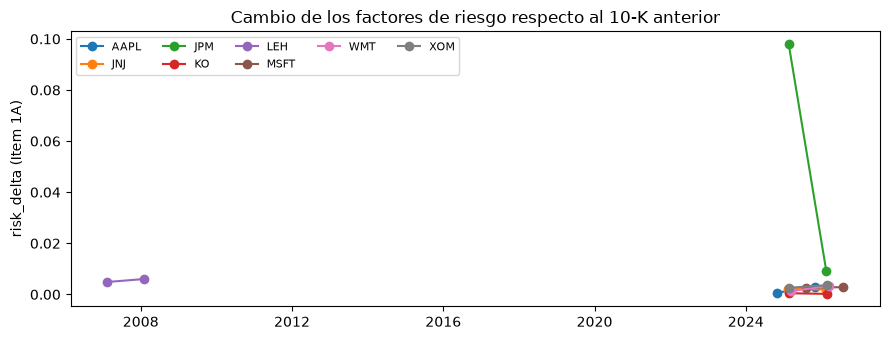

In [13]:
try:
    lm = sentimiento.cargar_lm()
    print('Diccionario LM:', {k: len(v) for k, v in lm.items()})
except FileNotFoundError as e:
    lm = None
    print('[aviso]', e)

sent = sonda.paso4_sentimiento(docs, lm)
if lm:
    display(sent.groupby(['ticker', 'tipo'])[['lm_negative', 'lm_uncertainty', 'lm_litigious', 'lm_tono']].mean().round(4))
rd = sent.dropna(subset=['risk_delta'])
if not rd.empty:
    fig, ax = plt.subplots(figsize=(9, 3.5))
    for tk, g in rd.groupby('ticker'):
        ax.plot(pd.to_datetime(g['fecha_publicacion']), g['risk_delta'], marker='o', label=tk)
    ax.set_ylabel('risk_delta (Item 1A)')
    ax.set_title('Cambio de los factores de riesgo respecto al 10-K anterior')
    ax.legend(ncol=5, fontsize=8)
    plt.tight_layout()
    plt.show()

## 7. Volumen: de 10 empresas a 500

Lo medido en la muestra, escalado a 500 empresas (orden de magnitud: las empresas grandes y antiguas de la
muestra presentan documentos más largos que la media). Sirve para decidir dónde guardar el corpus (Cloudflare R2
u otro). Con `MODO_RAPIDO` la extrapolación es por filing descargado, no del histórico entero: para el total,
multiplicar por `filings_totales / filings_muestra` de la tabla siguiente.

In [14]:
volumen = sonda.extrapolar_volumen(registro, n_empresas=len(cfg.empresas))
total = sonda.seleccion(filings, sonda.ConfigSonda(empresas=cfg.empresas, max_por_familia=None, verbose=False))
volumen['filings_totales_muestra'] = volumen['familia'].map(total.groupby('familia').size())
display(volumen.round(2))

,familia,filings_muestra,mb_muestra,mb_gz_muestra,filings_universo,gb_universo,gb_gz_universo,horas_descarga_universo,filings_totales_muestra
0,10-K,30,139.51,8.61,1500,6.98,0.43,0.29,281
1,10-Q,30,96.84,4.80,1500,4.84,0.24,0.22,844
2,8-K,27,13.85,0.62,1350,0.69,0.03,0.23,819


## 8. Fichas y tablas para el equipo

Se guardan las fichas de las cuatro fuentes (`results/ingesta/empresas/fichas/`) con lo medido, y las tablas
pequeñas de medición en CSV. Nada de esto contiene texto de los documentos: el corpus queda en local.

In [15]:
fichas = sonda.fichas_tema3(cobertura, registro, volumen, fundamentales, lm_disponible=lm is not None,
                            n_empresas=len(cfg.empresas))
sonda.guardar_tablas(cobertura=cobertura, timegate=timegate, extraccion_secciones=extraccion, volumen=volumen,
                     registro_descargas=registro.drop(columns=['cik']))
display(pd.DataFrame([{'fuente': f.fuente, 'estado': f.estado_sonda, 'desde': f.cobertura_inicio,
                       'retraso': f.retraso_publicacion, 'volumen': f.volumen_estimado} for f in fichas]))

,fuente,estado,desde,retraso,volumen
0,sec_10k_10q,ok,1994-03-11,10-K mediana 58.0 d tras el cierre del ejercic...,7.0 GB crudo / 0.4 GB gzip para 500 empresas (...
1,sec_8k_resultados,ok,2003-07-31,0 d (mismo día del anuncio; suele aceptarse tr...,0.7 GB crudo / 0.0 GB gzip para 500 empresas
2,sec_xbrl_companyfacts,ok,2009-07-23,el del filing que la contiene (10-K / 10-Q),258799 cifras en 10 empresas
3,loughran_mcdonald,ok,None,no aplica,~9 MB


## 9. Resumen para la reunión

Cifras impresas desde las tablas anteriores (nada escrito a mano).

In [16]:
def _primero(fam):
    c = cobertura.loc[cobertura['familia'] == fam, 'primero']
    return c.min() if not c.empty else None

print('DATOS DE EMPRESAS (SEC) — sonda con', len(cfg.empresas), 'empresas')
print(f"· 10-K desde {_primero('10-K')} · 10-Q desde {_primero('10-Q')} · 8-K de resultados desde {_primero('8-K resultados')}")
print(f"· Retraso mediano de publicación: 10-K {resumen.loc['10-K', 'retraso_mediana_d']:.0f} d · "
      f"10-Q {resumen.loc['10-Q', 'retraso_mediana_d']:.0f} d")
desfases = ', '.join(f"{h:+g} h ({n})" for h, n in timegate['desfase_h'].value_counts().items())
print(f"· TimeGate: hora oficial leída de {len(timegate)} filings · desfase de la API frente a la oficial: {desfases or 'sin datos'}")
print(f"· Secciones extraídas en {registro.loc[registro['familia'] != '8-K', 'ok'].mean():.0%} de los 10-K/10-Q descargados")
desaparecidas = sorted(set(filings.loc[~filings['activa'], 'ticker']))
print(f"· Desaparecidas presentes: {', '.join(desaparecidas) or 'ninguna (¡revisar: habría sesgo de supervivencia!)'}")
if not fundamentales.empty:
    print(f"· XBRL desde {fundamentales['fecha_publicacion'].min()} · {fundamentales['ticker'].nunique()} de {len(cfg.empresas)} empresas")
print(f"· Volumen estimado para 500 empresas (filings descargados): "
      f"{volumen['gb_universo'].sum():.1f} GB crudo / {volumen['gb_gz_universo'].sum():.1f} GB gzip")
print('\nPreguntas para decidir en grupo: universo (¿solo S&P 500?), ventana del backtest, '
      'fundamentales antes de 2009 (¿Compustat?), campo de texto en Documento.')

DATOS DE EMPRESAS (SEC) — sonda con 10 empresas
· 10-K desde 1994-03-11 · 10-Q desde 1994-01-26 · 8-K de resultados desde 2003-07-31
· Retraso mediano de publicación: 10-K 58 d · 10-Q 36 d
· TimeGate: hora oficial leída de 81 filings · desfase de la API frente a la oficial: +4 h (32), +5 h (22), +8 h (18), +10 h (9)
· Secciones extraídas en 95% de los 10-K/10-Q descargados
· Desaparecidas presentes: ENRNQ, LEH
· XBRL desde 2009-07-23 · 8 de 10 empresas
· Volumen estimado para 500 empresas (filings descargados): 12.5 GB crudo / 0.7 GB gzip

Preguntas para decidir en grupo: universo (¿solo S&P 500?), ventana del backtest, fundamentales antes de 2009 (¿Compustat?), campo de texto en Documento.
